<center><h1>Sarepaka_Abhishek_HW5</h1></center>
<br>
<br>

Name: Abhishek Sarepaka
<br>
Github Username: asarepaka
<br>
USC ID: 9325-5838-63

## 1. Decision Trees as Interpretable Models

Import packages

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
import xgboost as xgb

### (a) Obtain Data

Get the Accute Inamations Data Set

In [31]:
columns = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning_urethra', 'inflammation', 'nephritis']
df = pd.read_csv('/Users/abhisheksarepaka/Downloads/Homework 5 Data/diagnosis.data', header = None, sep = '\t', decimal = ',', names = columns, encoding = 'utf-16')

df[columns[1:]] = (df[columns[1:]] == 'yes').astype(int)
df

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...
115,41.4,0,1,1,0,1,0,1
116,41.5,0,0,0,0,0,0,0
117,41.5,1,1,0,1,0,0,1
118,41.5,0,1,1,0,1,0,1


In [32]:
features = columns[:6]
labels = ['inflammation', 'nephritis']
X_d = df[features]
Y_d = df[labels]
print(pd.crosstab(Y_d.inflammation, Y_d.nephritis))

nephritis      0   1
inflammation        
0             30  31
1             40  19


### (b) Build a decision tree

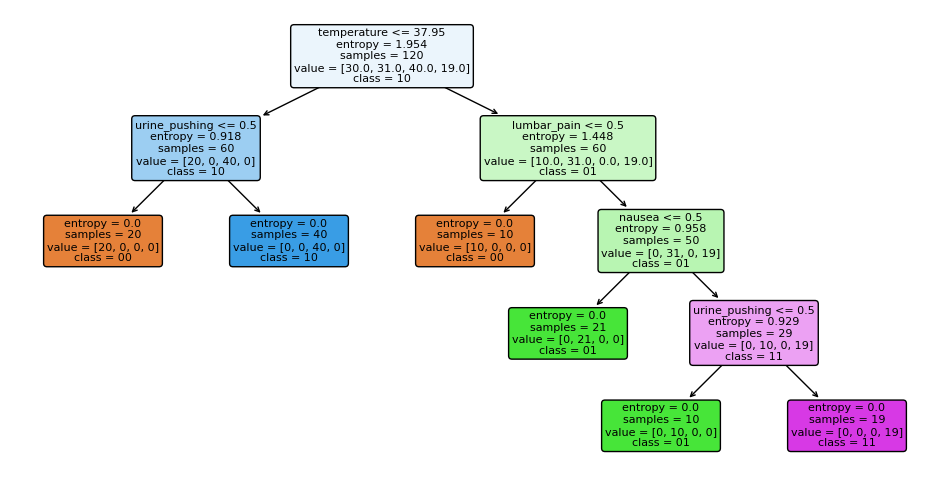

In [33]:
y_tree = Y_d.inflammation.astype(str) + Y_d.nephritis.astype(str)

tree_model = DecisionTreeClassifier(criterion = "entropy", random_state = 42)
tree_model.fit(X_d, y_tree)

plt.figure(figsize = (12, 6))
plot_tree(tree_model, feature_names = features, class_names = tree_model.classes_, filled = True, rounded = True, fontsize = 8)
plt.show()

The dataset has multiple labels for each example, so I used the Label Powerset method to handle the classification problem. This method treats each unique combination of labels as a separate class. I then trained a decision tree to predict these combinations. This also makes it easier to get decision rules from the tree, although the number of classes can increase if there are many different label combinations.

### (c) Convert the decision rules

In [34]:
def get_rules(tree, feature_names):
    t = tree.tree_
    rules = []
    def recurse(node, conditions):
        if t.children_left[node] == -1:
            label = tree.classes_[t.value[node].argmax()]
            rules.append("IF " + " AND ".join(conditions) + " THEN class = " + label)
            return
        name = feature_names[t.feature[node]]
        threshold = round(t.threshold[node], 3)
        recurse(t.children_left[node], conditions + [f"{name} <= {threshold}"])
        recurse(t.children_right[node], conditions + [f"{name} > {threshold}"])
    recurse(0, [])
    return rules

for rule in get_rules(tree_model, features):
    print(rule)

IF temperature <= 37.95 AND urine_pushing <= 0.5 THEN class = 00
IF temperature <= 37.95 AND urine_pushing > 0.5 THEN class = 10
IF temperature > 37.95 AND lumbar_pain <= 0.5 THEN class = 00
IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea <= 0.5 THEN class = 01
IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea > 0.5 AND urine_pushing <= 0.5 THEN class = 01
IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea > 0.5 AND urine_pushing > 0.5 THEN class = 11


### (d) Cost-complexity pruning

    alpha  leaves  cv_accuracy
0  0.0000       6       1.0000
1  0.1996       4       0.8667
2  0.3250       3       0.7667
3  0.4591       2       0.6333

Chosen alpha = 0.0000 | leaves = 6 | CV accuracy = 1.000


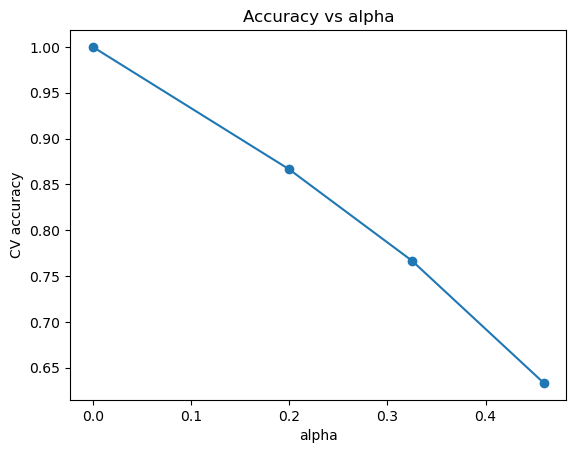

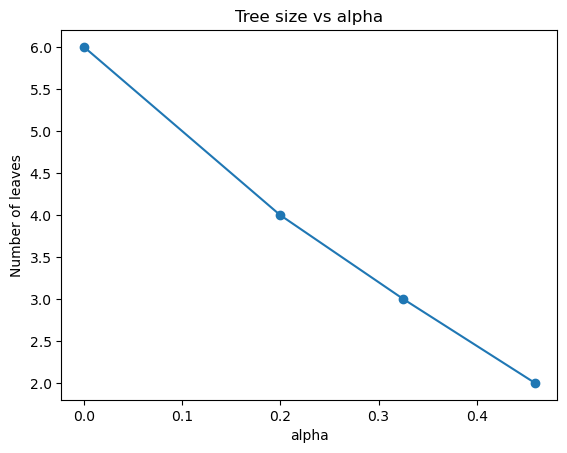

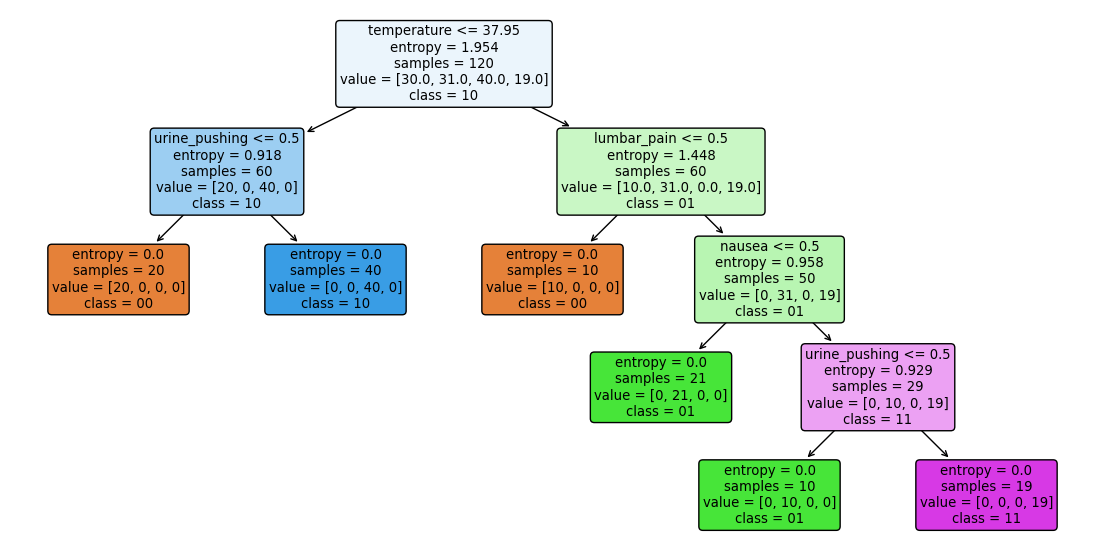

IF temperature <= 37.95 AND urine_pushing <= 0.5 THEN class = 00
IF temperature <= 37.95 AND urine_pushing > 0.5 THEN class = 10
IF temperature > 37.95 AND lumbar_pain <= 0.5 THEN class = 00
IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea <= 0.5 THEN class = 01
IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea > 0.5 AND urine_pushing <= 0.5 THEN class = 01
IF temperature > 37.95 AND lumbar_pain > 0.5 AND nausea > 0.5 AND urine_pushing > 0.5 THEN class = 11


In [35]:
path = tree_model.cost_complexity_pruning_path(X_d, y_tree)
alphas = path.ccp_alphas[:-1]

folds = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
rows = []
for a in alphas:
    t = DecisionTreeClassifier(criterion = "entropy", ccp_alpha = a, random_state = 42)
    acc = cross_val_score(t, X_d, y_tree, cv = folds).mean()
    leaves = t.fit(X_d, y_tree).get_n_leaves()
    rows.append((a, leaves, acc))
prune_df = pd.DataFrame(rows, columns = ['alpha', 'leaves', 'cv_accuracy'])
print(prune_df.round(4))

best_index = prune_df['cv_accuracy'].idxmax()
best_alpha = prune_df['alpha'][best_index]
best_acc = prune_df['cv_accuracy'][best_index]
pruned_tree = DecisionTreeClassifier(criterion = "entropy", ccp_alpha = best_alpha, random_state = 42).fit(X_d, y_tree)
print(f"\nChosen alpha = {best_alpha:.4f} | leaves = {pruned_tree.get_n_leaves()} | CV accuracy = {best_acc:.3f}")

plt.plot(prune_df['alpha'], prune_df['cv_accuracy'], marker = 'o')
plt.xlabel('alpha')
plt.ylabel('CV accuracy')
plt.title('Accuracy vs alpha')
plt.show()

plt.plot(prune_df['alpha'], prune_df['leaves'], marker = 'o')
plt.xlabel('alpha')
plt.ylabel('Number of leaves')
plt.title('Tree size vs alpha')
plt.show()

plt.figure(figsize = (14, 7))
plot_tree(pruned_tree, feature_names = features, class_names = pruned_tree.classes_, filled = True, rounded = True)
plt.show()

for rule in get_rules(pruned_tree, features):
    print(rule)

Only a = 0 achieves a 100 percent cross-validation accuracy. Increasing a would remove the splits that are important for accurate classification, causing accuracy to decline quickly. This indicates that the six leaf tree is already the minimal tree that maintains perfect accuracy, which means that the rules from part c represent the final set. One interesting thing I noticed is that neither micturition pains nor burning of the urethra is used in the final decision tree.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [36]:
names = []
for line in open('/Users/abhisheksarepaka/Downloads/Homework 5 Data/communities.names'):
    if line.startswith('@attribute'):
        names.append(line.split()[1])

crime = pd.read_csv('/Users/abhisheksarepaka/Downloads/Homework 5 Data/communities.data', header = None, names = names, na_values = '?')
print(len(names), crime.shape)
crime.head()

128 (1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [37]:
crime = crime.drop(columns = ['state', 'county', 'community', 'communityname', 'fold'])
target = 'ViolentCrimesPerPop'
miss = crime.isna().sum(); print('Columns with missing values:'); print(miss[miss > 0])

train, test = crime.iloc[:1495].copy(), crime.iloc[1495:].copy()
imp = SimpleImputer(strategy = 'median').fit(train)
train = pd.DataFrame(imp.transform(train), columns = crime.columns)
test = pd.DataFrame(imp.transform(test), columns = crime.columns)
X_tr, y_tr = train.drop(columns = target), train[target]
X_te, y_te = test.drop(columns = target), test[target]
print('\nTrain:', X_tr.shape, ' Test:', X_te.shape, ' Missing left:', int(train.isna().sum().sum() + test.isna().sum().sum()))

Columns with missing values:
OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64

Train: (1495, 122)  Test: (499, 122)  Missing left: 0


### (c) Plot a correlation matrix

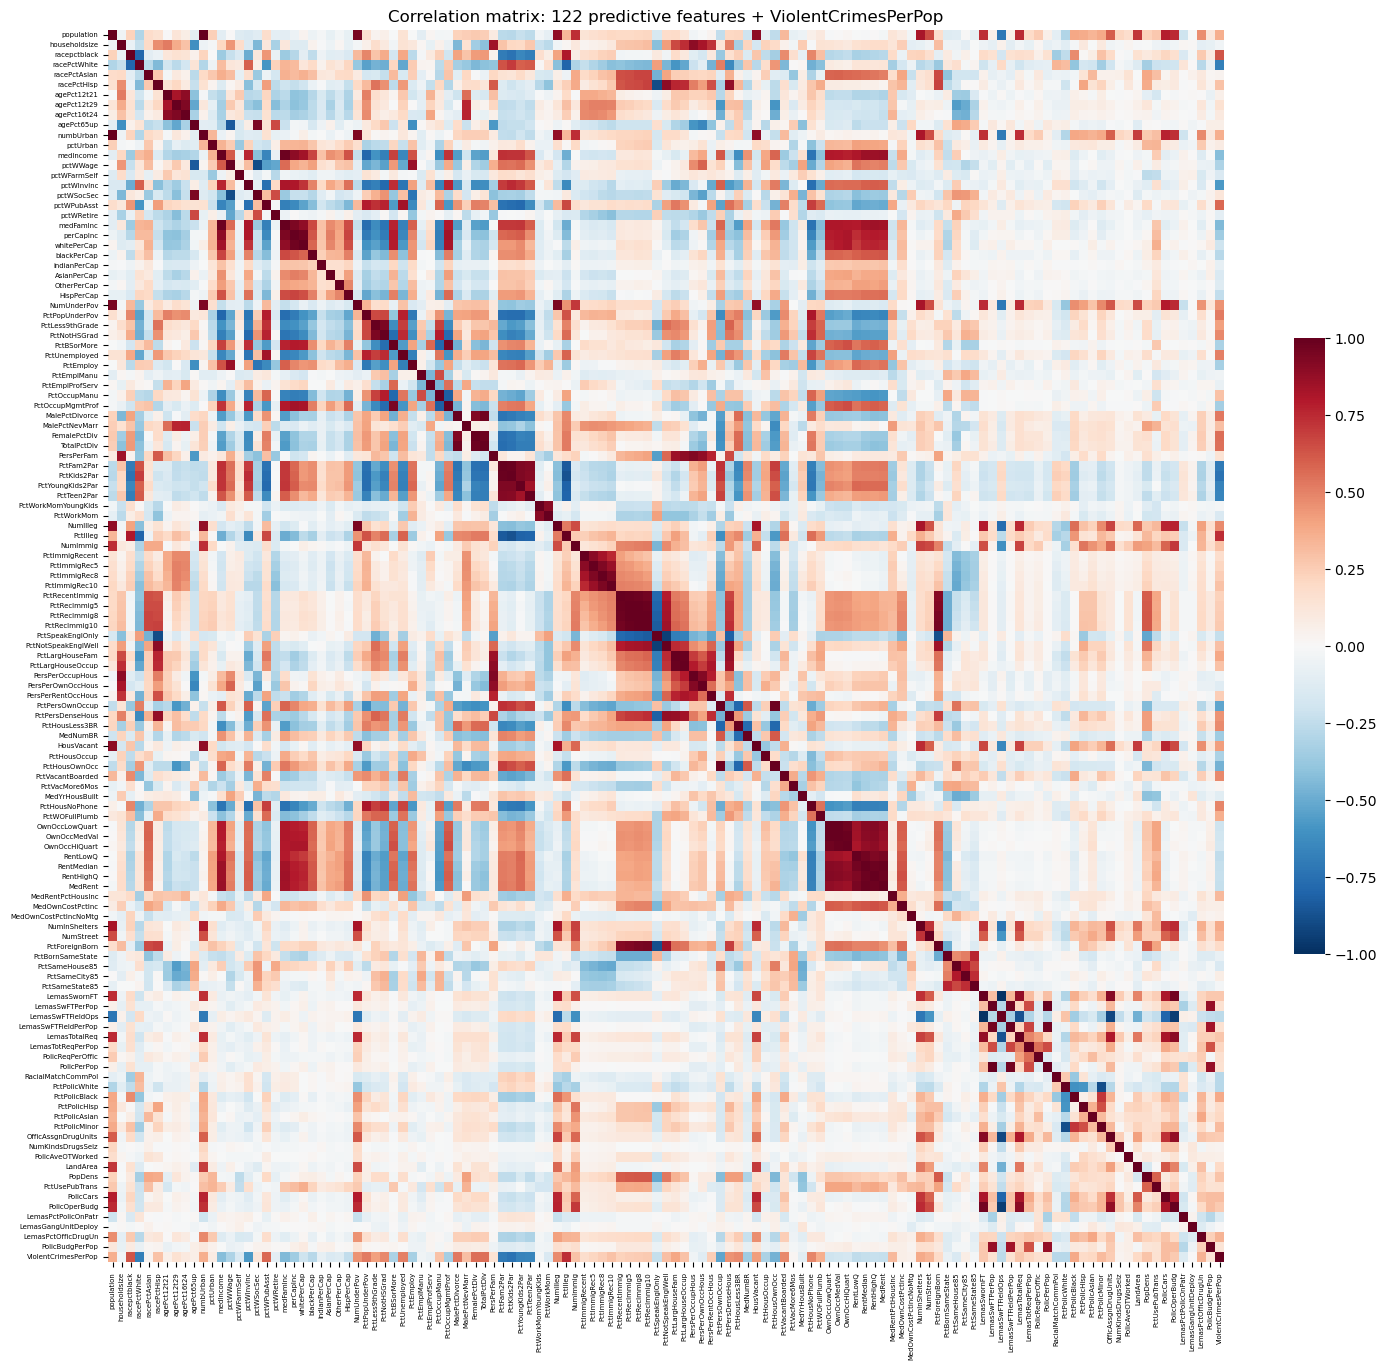

Features most correlated with the target:
PctKids2Par        -0.738
PctIlleg            0.738
PctFam2Par         -0.707
racePctWhite       -0.685
PctYoungKids2Par   -0.666
PctTeen2Par        -0.662
racepctblack        0.631
pctWInvInc         -0.576
pctWPubAsst         0.575
FemalePctDiv        0.556
Name: ViolentCrimesPerPop, dtype: float64


In [38]:
full = pd.concat([train, test], ignore_index = True)
corr = full.corr()

plt.figure(figsize = (18, 16))
sns.heatmap(corr, cmap = 'RdBu_r', vmin = -1, vmax = 1, xticklabels = True, yticklabels = True, cbar_kws = {'shrink': .5})
plt.xticks(fontsize = 5)
plt.yticks(fontsize = 5)
plt.title('Correlation matrix: 122 predictive features + ViolentCrimesPerPop')
plt.show()

corr_target = corr[target].drop(target)
order = corr_target.abs().sort_values(ascending = False).index
print('Features most correlated with the target:')
print(corr_target[order].head(10).round(3))

### (d) Calculate the Coefficient of Variation CV

In [39]:
Xfull = full.drop(columns = target)
cv = (Xfull.std(ddof = 1) / Xfull.mean()).sort_values(ascending = False)
cv_df = cv.rename('CV').to_frame()
cv_df

,CV
PctPolicAsian,5.447835
NumStreet,4.407702
NumInShelters,3.485481
NumIlleg,2.994196
NumImmig,2.900497
...,...
NumKindsDrugsSeiz,0.143227
RacialMatchCommPol,0.126902
LemasPctPolicOnPatr,0.117807
PctPolicWhite,0.117726


### (e) Scatter plots and box plots for highest CV features

11 ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


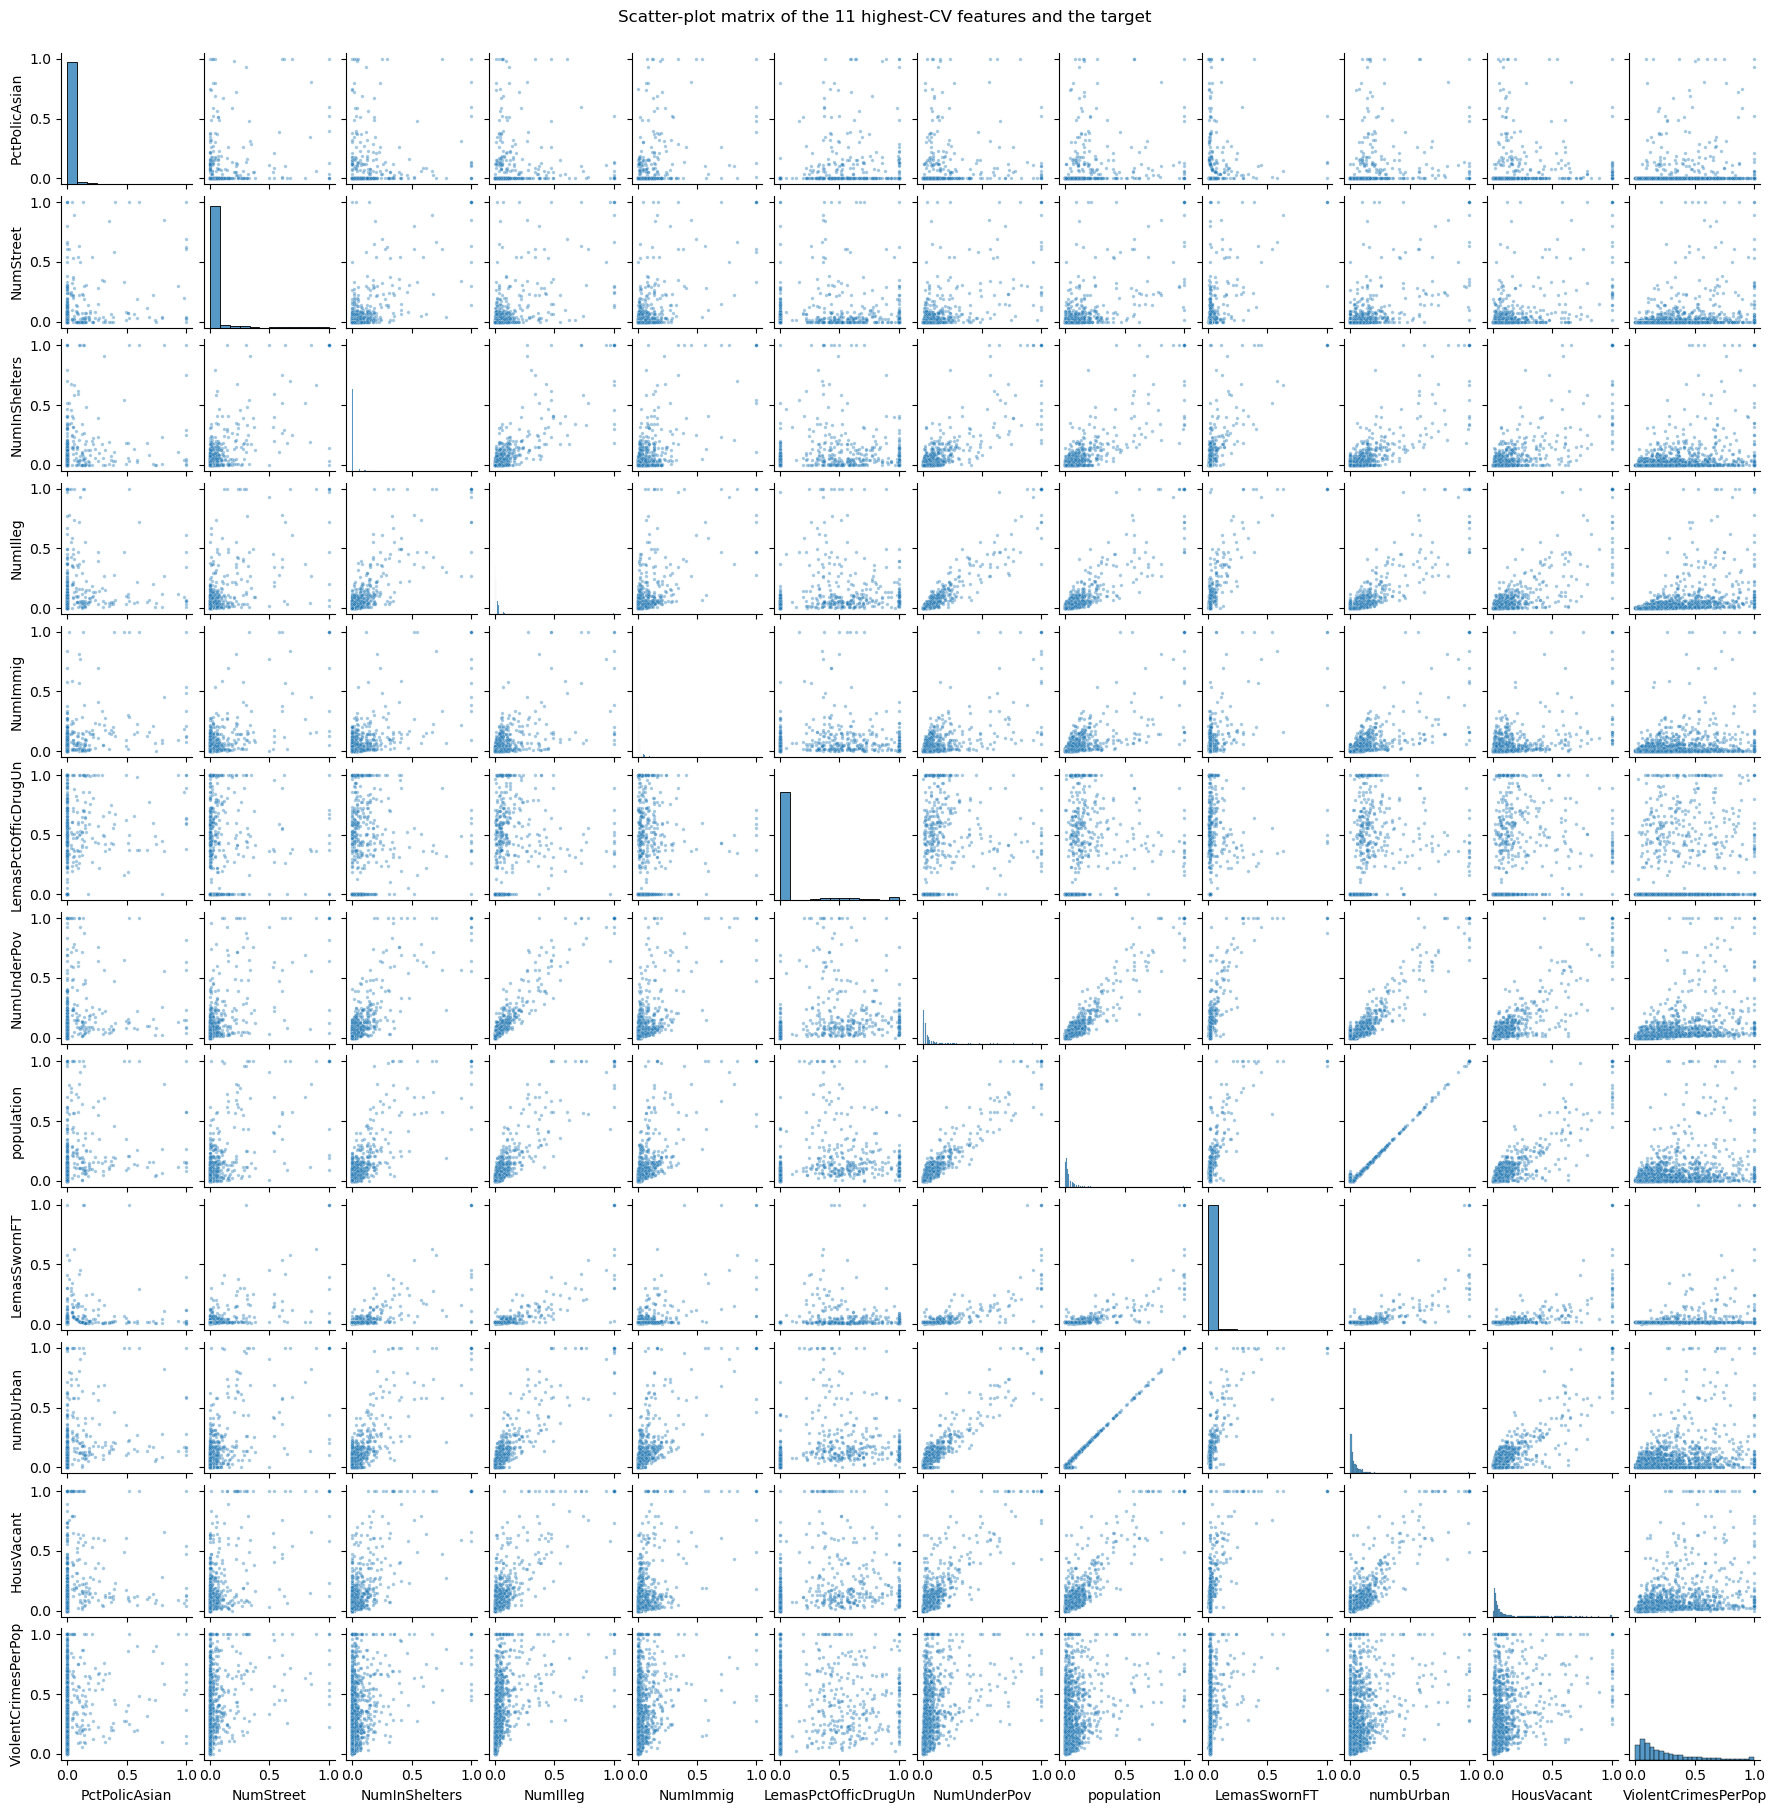

In [40]:
k = int(np.floor(np.sqrt(128)))
top = cv.index[:k].tolist()
print(k, top)

sns.pairplot(full[top + [target]], plot_kws = {'s': 6, 'alpha': .4}, diag_kind = 'hist', height = 1.5)
plt.suptitle('Scatter-plot matrix of the 11 highest-CV features and the target', y = 1.01)
plt.show()

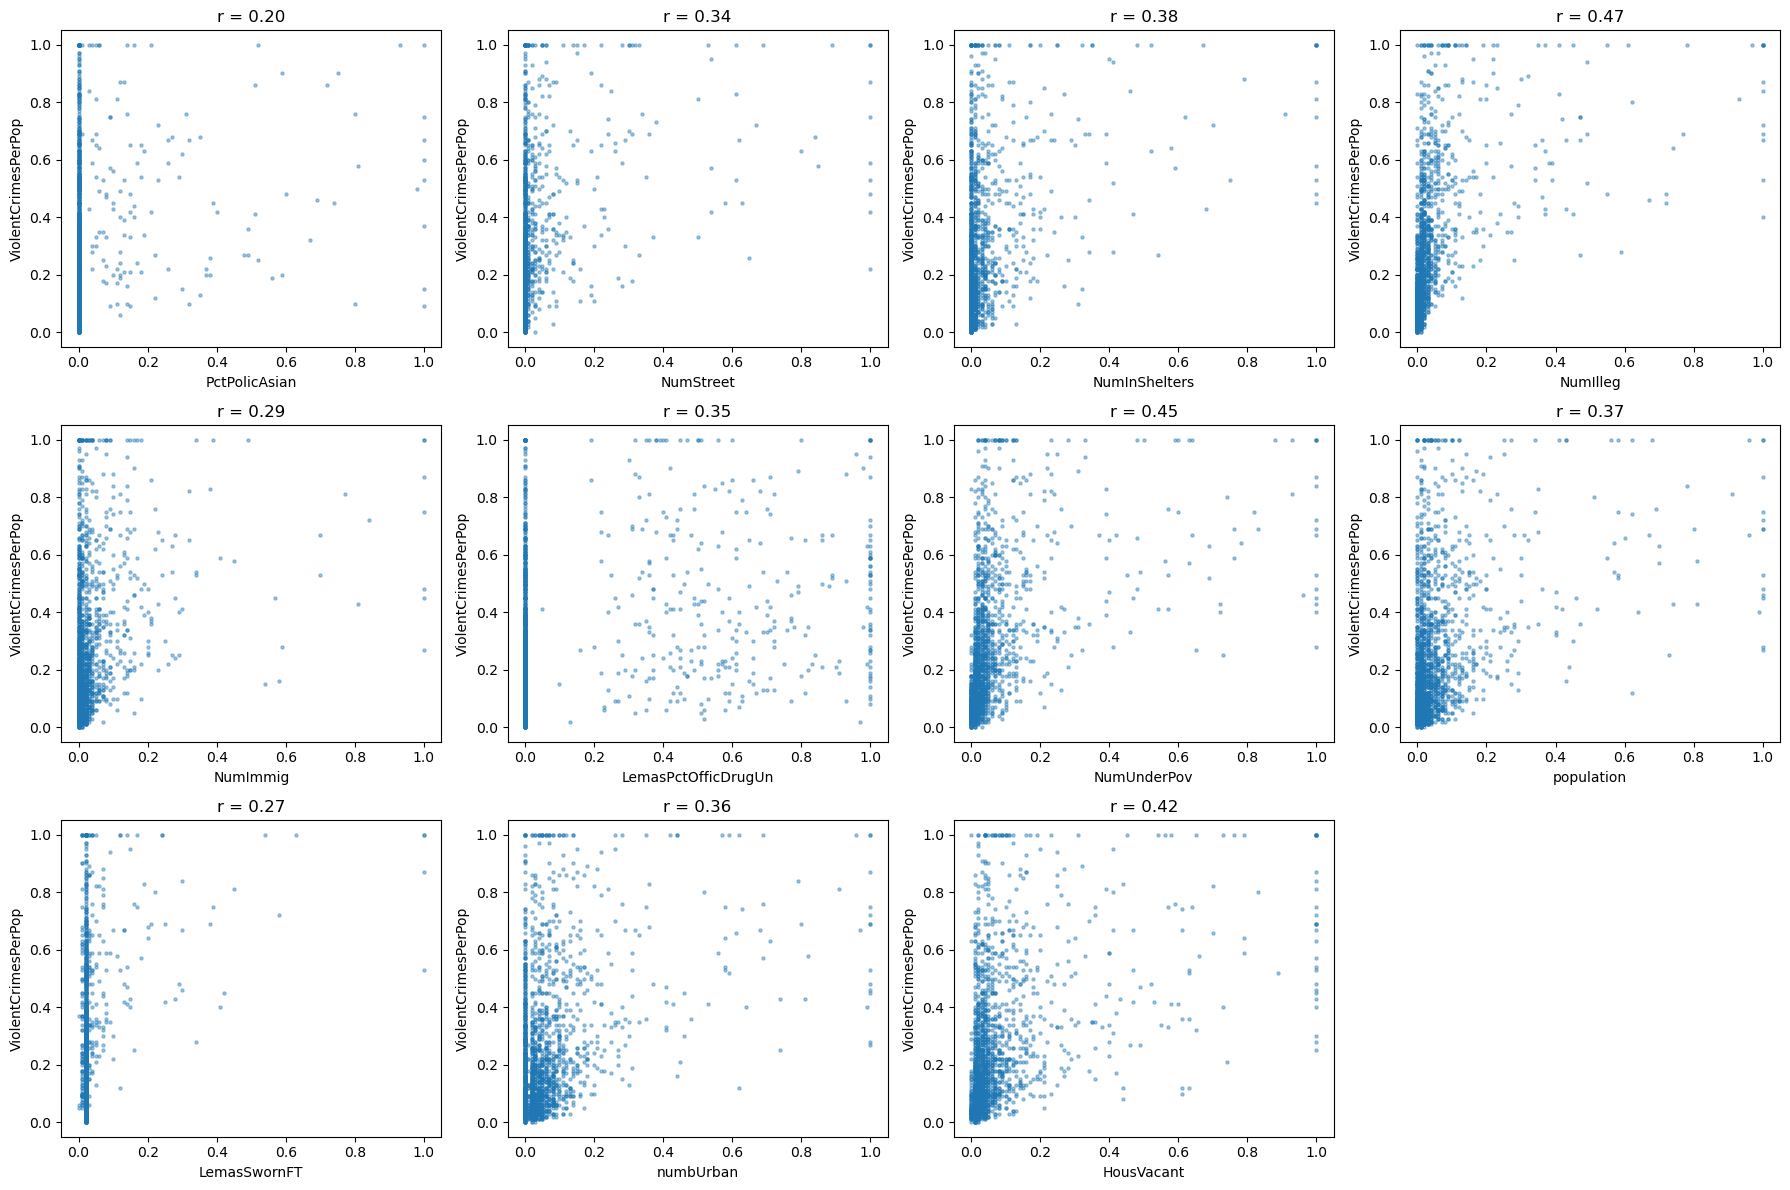

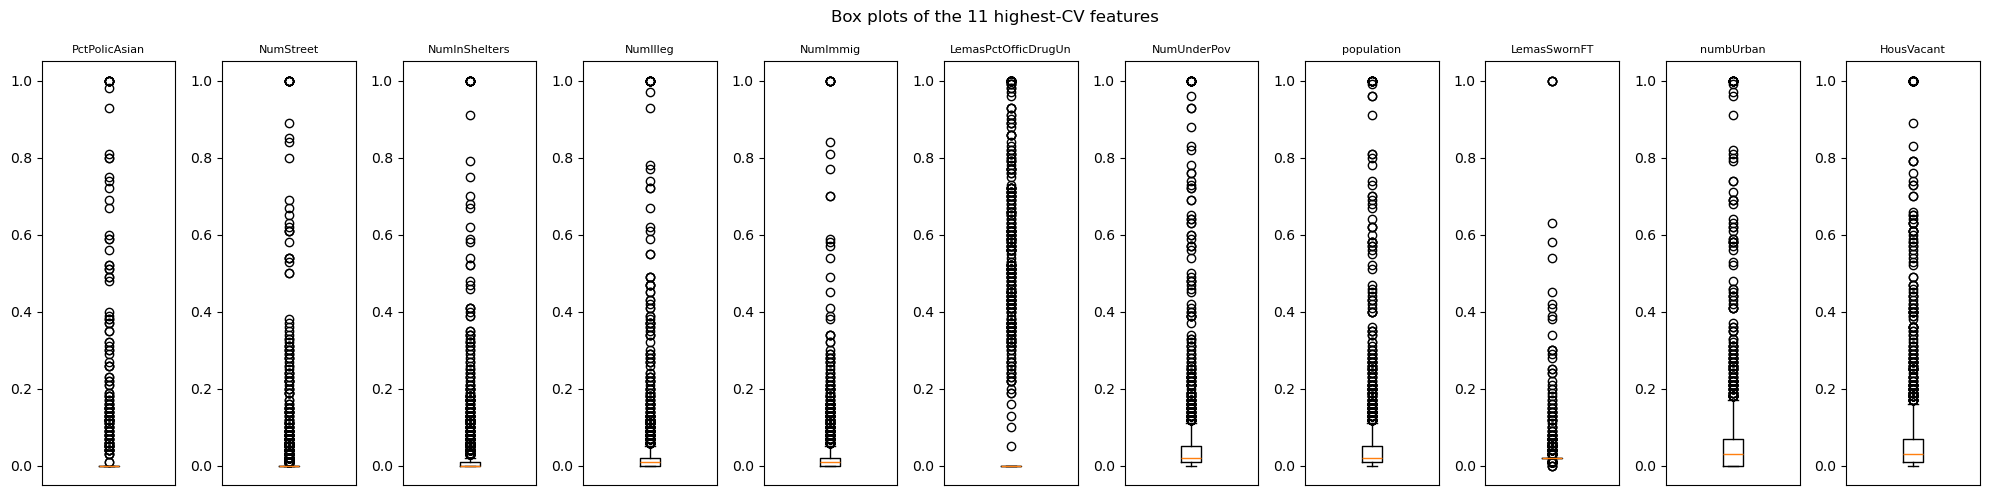

In [41]:
fig, axes = plt.subplots(3, 4, figsize = (18, 12))
for ax, f in zip(axes.flat, top):
    ax.scatter(full[f], full[target], s = 5, alpha = .4)
    ax.set_xlabel(f)
    ax.set_ylabel(target)
    ax.set_title(f'r = {full[f].corr(full[target]):.2f}')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, k, figsize = (20, 5))
for ax, f in zip(axes, top):
    ax.boxplot(full[f])
    ax.set_title(f, fontsize = 8)
    ax.set_xticks([])
plt.suptitle('Box plots of the 11 highest-CV features')
plt.tight_layout()
plt.show()

From the scatter plots I don't think we can really tell which features are significant. Some of them look like they might have a slight relationship with crime but there is a lot of spread so it's hard to say. We would need to do a regression to find out.

### (f) Fit a linear model

In [42]:
results = {}
ols = LinearRegression().fit(X_tr, y_tr)
results['OLS'] = mean_squared_error(y_te, ols.predict(X_te))
print(f"OLS test MSE = {results['OLS']:.5f}")

OLS test MSE = 0.01797


### (g) Fit a ridge regression model

In [43]:
kf = KFold(n_splits = 10, shuffle = True, random_state = 42)
lam_grid = np.logspace(-4, 4, 200)
ridge = RidgeCV(alphas = lam_grid, cv = kf, scoring = 'neg_mean_squared_error').fit(X_tr, y_tr)
results['Ridge'] = mean_squared_error(y_te, ridge.predict(X_te))
print(f"Ridge: best lambda = {ridge.alpha_:.4f}, test MSE = {results['Ridge']:.5f}")

Ridge: best lambda = 3.1806, test MSE = 0.01748


### (h) Fit a LASSO model

In [44]:
lasso = LassoCV(cv = kf, alphas = np.logspace(-4, 4, 200), max_iter = 50000, random_state = 42).fit(X_tr, y_tr)
results['LASSO (raw)'] = mean_squared_error(y_te, lasso.predict(X_te))
sel = pd.Series(lasso.coef_, index = X_tr.columns)
sel = sel[sel != 0].sort_values(key = abs, ascending = False)
print(f"LASSO raw: lambda = {lasso.alpha_:.6f}, test MSE = {results['LASSO (raw)']:.5f}, {len(sel)} variables selected")

lasso_std = Pipeline([('sc', StandardScaler()), ('lasso', LassoCV(cv = kf, alphas = np.logspace(-4, 4, 200), max_iter = 50000, random_state = 42))]).fit(X_tr, y_tr)
results['LASSO (standardized)'] = mean_squared_error(y_te, lasso_std.predict(X_te))
L = lasso_std.named_steps['lasso']
sel_std = pd.Series(L.coef_, index = X_tr.columns)
sel_std = sel_std[sel_std != 0].sort_values(key = abs, ascending = False)
print(f"LASSO standardized: lambda = {L.alpha_:.6f}, test MSE = {results['LASSO (standardized)']:.5f}, {len(sel_std)} variables selected")

print('Selected in both:', len(set(sel.index) & set(sel_std.index)))
sel_std.round(4).to_frame('coef (standardized scale)')

LASSO raw: lambda = 0.000120, test MSE = 0.01763, 74 variables selected
LASSO standardized: lambda = 0.000637, test MSE = 0.01772, 76 variables selected
Selected in both: 73


,coef (standardized scale)
racepctblack,0.0680
PctPersDenseHous,0.0432
agePct12t29,-0.0430
PctKids2Par,-0.0406
RentLowQ,-0.0307
...,...
PctOccupManu,0.0007
MedNumBR,0.0007
PctImmigRec10,-0.0006
PersPerOwnOccHous,-0.0003


Raw and standardized lasso produce very similar results, with test mse of 0.01763 and 0.01772 and 73 selected variables in common. This is expected because the features are already normalized between 0 and 1, so standardization has only a small effect on the penalty. Both the lasso models slightly outperform ordinary least squares while selecting only about 75 of the 122 variables. However, the differences in performance are relatively small, so neither model demonstrates a substantial advantage over the others.

### (i) Fit a PCR model

PCR: best M = 96, test MSE = 0.01833


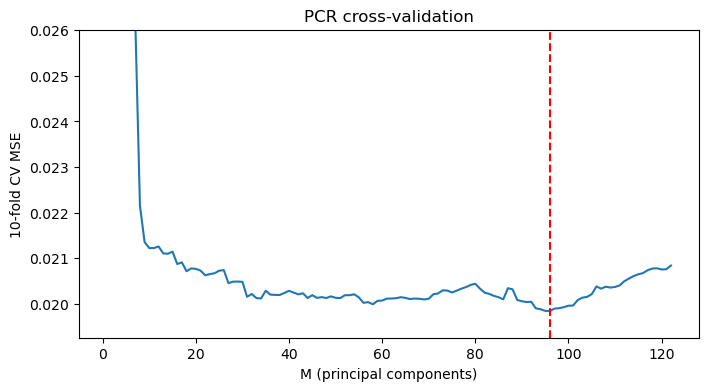

In [45]:
pcr = Pipeline([('sc', StandardScaler()), ('pca', PCA()), ('lr', LinearRegression())])
gs_pcr = GridSearchCV(pcr, {'pca__n_components': range(1, X_tr.shape[1] + 1)}, cv = kf, scoring = 'neg_mean_squared_error').fit(X_tr, y_tr)
M = gs_pcr.best_params_['pca__n_components']
results['PCR'] = mean_squared_error(y_te, gs_pcr.predict(X_te))
print(f"PCR: best M = {M}, test MSE = {results['PCR']:.5f}")
plt.figure(figsize = (8, 4))
plt.plot(range(1, X_tr.shape[1] + 1), -gs_pcr.cv_results_['mean_test_score'])
plt.axvline(M, ls = '--', c = 'r')
plt.xlabel('M (principal components)')
plt.ylabel('10-fold CV MSE')
plt.ylim(None, np.percentile(-gs_pcr.cv_results_['mean_test_score'], 95))
plt.title('PCR cross-validation')
plt.show()

### (j) Fit a boosting tree

XGBoost: best alpha = 2, test MSE = 0.01562
      alpha   cv_mse
0    0.0000  0.01996
1    0.0001  0.01983
2    0.0010  0.01975
3    0.0100  0.01973
4    0.0500  0.01973
5    0.1000  0.01986
6    0.5000  0.01984
7    1.0000  0.01976
8    2.0000  0.01955
9    5.0000  0.02022
10  10.0000  0.02123


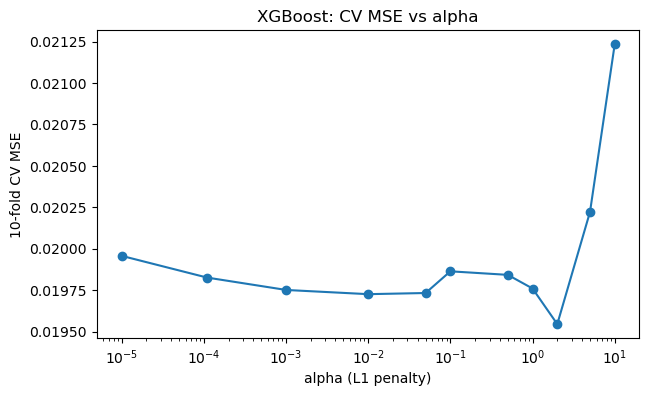

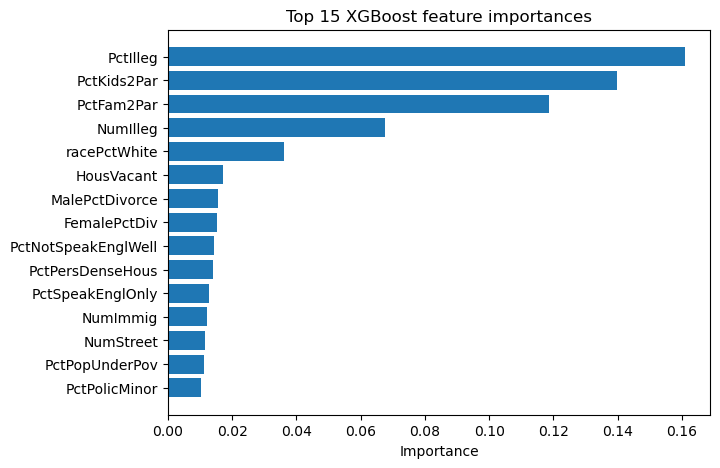

In [46]:
xgb_base = xgb.XGBRegressor(n_estimators = 400, learning_rate = 0.05, max_depth = 3, subsample = 0.8, colsample_bytree = 0.5, objective = 'reg:squarederror', random_state = 42, n_jobs = -1)
alpha_grid = {'reg_alpha': [0, 1e-4, 1e-3, 1e-2, 0.05, 0.1, 0.5, 1, 2, 5, 10]}
gs_xgb = GridSearchCV(xgb_base, alpha_grid, cv = kf, scoring = 'neg_mean_squared_error', n_jobs = 1).fit(X_tr, y_tr)
a_best = gs_xgb.best_params_['reg_alpha']
results['XGBoost (L1)'] = mean_squared_error(y_te, gs_xgb.predict(X_te))
print(f"XGBoost: best alpha = {a_best}, test MSE = {results['XGBoost (L1)']:.5f}")
cvres = pd.DataFrame({'alpha': alpha_grid['reg_alpha'], 'cv_mse': -gs_xgb.cv_results_['mean_test_score']})
print(cvres.round(5))
plt.figure(figsize = (7, 4)); plt.semilogx(np.array(alpha_grid['reg_alpha']) + 1e-5, cvres.cv_mse, marker = 'o')
plt.xlabel('alpha (L1 penalty)'); plt.ylabel('10-fold CV MSE'); plt.title('XGBoost: CV MSE vs alpha'); plt.show()

importances = gs_xgb.best_estimator_.feature_importances_
imp_df = pd.DataFrame({'feature': X_tr.columns, 'importance': importances})
imp_df = imp_df.sort_values('importance', ascending = False).head(15)

plt.figure(figsize = (7, 5))
plt.barh(imp_df['feature'], imp_df['importance'])
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('Top 15 XGBoost feature importances')
plt.show()